# Project 1: Understanding CUDA Acceleration in Neural Networks

### Instructor : Othmane K

### A hands-on exploration using CIFAR-10 classification with a CNN

In this notebook, we’ll walk through how **GPU acceleration (CUDA)** dramatically speeds up deep learning training — not just by offloading computation, but by optimizing the *entire data pipeline*. We’ll use your project (CIFAR-10 + CNN) as our case study.

🔹 **Key Concepts Covered**:
- Why GPUs help (parallelism vs. CPUs)
- The hidden bottleneck: host-to-device data transfer
- `pin_memory=True`: what it does & why it matters
- `num_workers`: balancing CPU parallelism vs. overhead
- Profiler insights: where time is actually spent

💡 *You’ll run experiments, tweak parameters, and see real speedups — all in your browser.*

In [1]:
# Install dependencies (run once if needed)
# !pip install torch torchvision numpy matplotlib ipywidgets

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, SubsetRandomSampler
import numpy as np
import matplotlib.pyplot as plt
import time
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

# Ensure CUDA is available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"✅ Using device: {device}")

✅ Using device: cuda


---
## 1. The Baseline: Training on CPU

Let’s start with the slowest (but most portable) setup: **no GPU**, all computation on CPU.

We’ll train a simple CNN on CIFAR-10 for **1 epoch** — just enough to measure timing.


---

## Define the Network [Architecture](http://pytorch.org/docs/stable/nn.html)

This time, you'll define a CNN architecture. Instead of an MLP, which used linear, fully-connected layers, you'll use the following:
* [Convolutional layers](https://pytorch.org/docs/stable/nn.html#conv2d), which can be thought of as stack of filtered images.
* [Maxpooling layers](https://pytorch.org/docs/stable/nn.html#maxpool2d), which reduce the x-y size of an input, keeping only the most _active_ pixels from the previous layer.
* The usual Linear + Dropout layers to avoid overfitting and produce a 10-dim output.

A network with 2 convolutional layers is shown in the image below and in the code, and you've been given starter code with one convolutional and one maxpooling layer.

#### TO DO: Define a model with multiple convolutional layers, and define the feedforward metwork behavior.

You can also define a custom architecture like Resnet, Inception...



In [6]:
import matplotlib.pyplot as plt
# Define the CNN architecture (same as your project)
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.conv1 = nn.Conv2d(3, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(64 * 4 * 4, 500)
        self.fc2 = nn.Linear(500, 10)
        self.dropout = nn.Dropout(0.25)
    
    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))
        x = self.pool(torch.relu(self.conv3(x)))
        x = x.view(-1, 64 * 4 * 4)
        x = self.dropout(x)
        x = torch.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

# Data preprocessing
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# Load dataset (small subset for fast demo)
train_set = datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
subset_indices = list(range(10000))  # Only 1000 samples for speed
train_sampler = SubsetRandomSampler(subset_indices)
batch_size = 64

# CPU-only training function
def train_cpu(n_epochs=1, lr=0.01, momentum=0.9,plot=None):
    model = Net().cpu()
    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=momentum)
    criterion = nn.CrossEntropyLoss()
    
    train_loader = torch.utils.data.DataLoader(train_set, batch_size=batch_size, sampler=train_sampler, num_workers=0)
    
    start = time.time()
    model.train()
    for epoch in range(n_epochs):
        for data, target in train_loader:
            # No GPU transfer here!
            optimizer.zero_grad()
            output = model(data)
            loss = criterion(output, target)
            loss.backward()
            optimizer.step()
    end = time.time()

    if plot :
        classes = ['airplane', 'automobile', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck']
        # Obtain one batch of training images
        dataiter = iter(train_loader)
        images, labels = next(dataiter)  # Use next() correctly to retrieve the batch
        images = images.numpy()  # Convert images to numpy for display

        # Plot the images in the batch, along with the corresponding labels
        fig = plt.figure(figsize=(25, 4))

        # Display 20 images
        for idx in np.arange(20):
            ax = fig.add_subplot(2, 10, idx + 1, xticks=[], yticks=[])
            img = images[idx]
            img = np.transpose(img, (1, 2, 0))  # CHW to HWC
            img = img * 0.5 + 0.5  # unnormalize
            plt.imshow(img)
            ax.set_title(classes[labels[idx].item()])
        plt.show()

    return end - start

#### Data Vizualisation

⏳ Running CPU-only training (3 epochs, 10000 samples)...


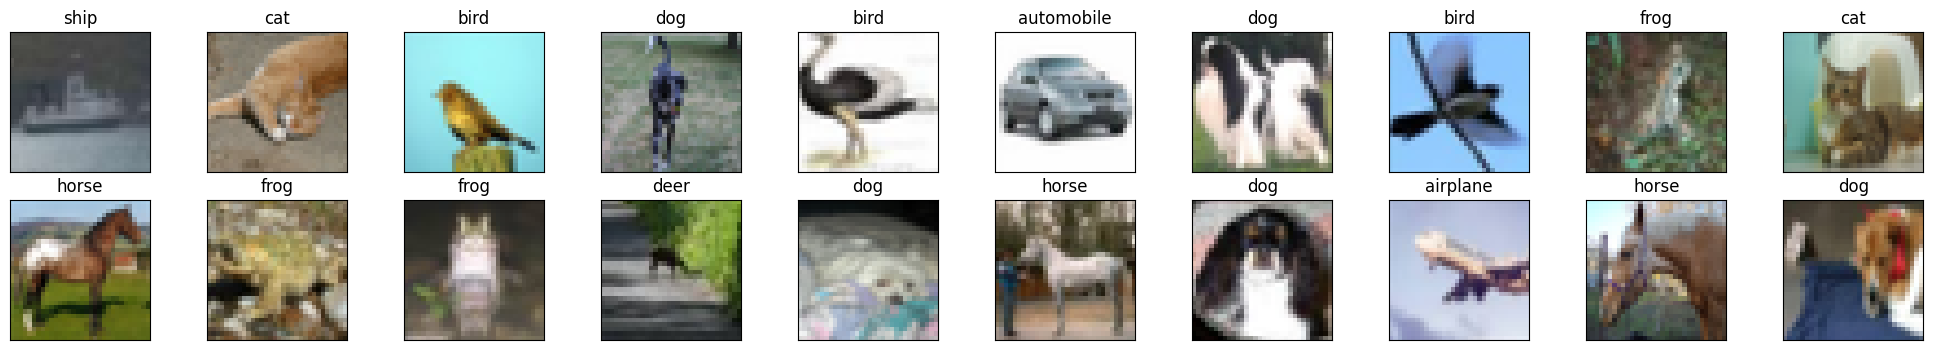

✅ CPU training time: 20.45 seconds


In [6]:
# ⏱️ Measure CPU training time
print("⏳ Running CPU-only training (3 epochs, 10000 samples)...")
cpu_time = train_cpu(n_epochs=3,plot=True)
print(f"✅ CPU training time: {cpu_time:.2f} seconds")

---
## 2. First Speedup: Move Computation to GPU (CUDA)

Now let’s move the model and data to the GPU using `.to('cuda')`.

> ⚠️ **Critical Insight**: Just moving the model to GPU *is not enough*. If data stays on CPU, PyTorch must copy each batch to GPU *synchronously* — this becomes the bottleneck!

In [7]:
# GPU training (without optimizations)
def train_gpu_basic(n_epochs=1, lr=0.01, momentum=0.9):
    model = Net().to(device)
    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=momentum)
    criterion = nn.CrossEntropyLoss()
    
    train_loader = DataLoader(train_set, batch_size=batch_size, sampler=train_sampler, num_workers=0)
    
    start = time.time()
    model.train()
    for epoch in range(n_epochs):
        for data, target in train_loader:
            # ⚠️ Still copying data from CPU → GPU *every batch*, synchronously
            data, target = data.to(device), target.to(device)
            optimizer.zero_grad()
            output = model(data)
            loss = criterion(output, target)
            loss.backward()
            optimizer.step()
    end = time.time()
    return end - start

In [8]:
print("⏳ Running GPU training (basic, no optimizations)...")
gpu_basic_time = train_gpu_basic(n_epochs=3)
print(f"✅ GPU (basic) training time: {gpu_basic_time:.2f} seconds")
print(f"📈 Speedup vs CPU: {cpu_time/gpu_basic_time:.2f}x")

⏳ Running GPU training (basic, no optimizations)...
✅ GPU (basic) training time: 11.11 seconds
📈 Speedup vs CPU: 1.84x


### 📊 Compare CPU vs Basic GPU

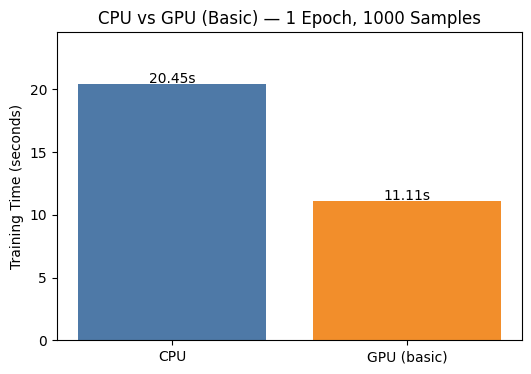

In [9]:
labels = ['CPU', 'GPU (basic)']
times = [cpu_time, gpu_basic_time]

plt.figure(figsize=(6, 4))
bars = plt.bar(labels, times, color=['#4e79a7', '#f28e2b'])
plt.ylabel('Training Time (seconds)')
plt.title('CPU vs GPU (Basic) — 1 Epoch, 1000 Samples')
for i, (bar, t) in enumerate(zip(bars, times)):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05, f'{t:.2f}s', ha='center')
plt.ylim(0, max(times)*1.2)
plt.show()

---
## 3. The Hidden Bottleneck: Host-to-Device Transfer

Let’s profile what’s *actually* happening during GPU training.

Using `torch.profiler`, we can see that a large fraction of time is spent in:
- `aten::to` (copying tensors to GPU)
- `aten::copy_` (host → device memory transfer)

This is the **data pipeline bottleneck** — even with a fast GPU, if data can’t keep up, the GPU sits idle.

In [10]:
from torch.profiler import profile, record_function, ProfilerActivity

def profile_gpu_basic():
    model = Net().to(device)
    optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.9)
    criterion = nn.CrossEntropyLoss()
    
    train_loader = DataLoader(train_set, batch_size=batch_size, sampler=train_sampler, num_workers=0)
    
    with profile(activities=[ProfilerActivity.CPU, ProfilerActivity.CUDA],
                 record_shapes=True, profile_memory=True) as prof:
        model.train()
        for data, target in train_loader:
            data, target = data.to(device), target.to(device)
            with record_function("model_inference"):
                optimizer.zero_grad()
                output = model(data)
                loss = criterion(output, target)
                loss.backward()
                optimizer.step()
            #break  # Only profile 1 batch
    return prof

print("🔍 Profiling 1 batch (GPU basic)...")
prof = profile_gpu_basic()
print(prof.key_averages().table(sort_by="cuda_time_total", row_limit=10))

🔍 Profiling 1 batch (GPU basic)...
-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                                   Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg     Self CUDA   Self CUDA %    CUDA total  CUDA time avg       CPU Mem  Self CPU Mem      CUDA Mem  Self CUDA Mem    # of Calls  
-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                        model_inference        10.64%     666.567ms        17.45%        1.094s       6.967ms       0.000us         0.00%     582.527ms       3.710ms           0 b      

💡 **What you see**:
- `aten::to` and `aten::copy_` dominate the CUDA time.
- The actual model forward/backward (`conv2d`, `linear`) is fast — but waits for data.

➡️ **Solution**: Use **pinned memory** + **asynchronous transfers**.

---
## 4. Optimization 1: Pinned Memory (`pin_memory=True`)

### What is pinned memory?
- Normal RAM: pageable → OS can swap pages to disk → **slow transfers**.
- Pinned (page-locked) memory: fixed in RAM → GPU DMA can copy directly → **much faster**.

### How to enable:
```python
DataLoader(..., pin_memory=True)
```

⚠️ Trade-off: Uses more RAM and may affect other processes. But for training? Worth it!

In [23]:
def train_gpu_pinned(n_epochs=1, lr=0.01, batch_size=64, momentum=0.9, ASYNC_DATATRANSFER=False):
    model = Net().to(device)
    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=momentum)
    criterion = nn.CrossEntropyLoss()        
    
    # 🔑 Enable pinned memory!
    train_loader = DataLoader(train_set, batch_size=batch_size, sampler=train_sampler, 
                              num_workers=0, pin_memory=True)
    
    start = time.time()
    model.train()
    print(f"⚡ Training on GPU with pinned memory (batch_size={batch_size}, async_transfer={ASYNC_DATATRANSFER})...")
    for epoch in range(n_epochs):
        print(f"  Epoch {epoch+1}/{n_epochs}...")
        for data, target in train_loader:
            data, target = data.to(device,non_blocking=ASYNC_DATATRANSFER), target.to(device,non_blocking=ASYNC_DATATRANSFER)
            optimizer.zero_grad()
            output = model(data)
            loss = criterion(output, target)
            loss.backward()
            optimizer.step()
    end = time.time()
    return end - start

In [12]:
print("⏳ Running GPU training with pinned memory...")
gpu_pinned_time = train_gpu_pinned(n_epochs=1)
print(f"✅ GPU (pinned) training time: {gpu_pinned_time:.2f} seconds")
print(f"📈 Speedup vs basic GPU: {gpu_basic_time/gpu_pinned_time:.2f}x")

⏳ Running GPU training with pinned memory...
✅ GPU (pinned) training time: 7.39 seconds
📈 Speedup vs basic GPU: 1.50x


### 📊 Compare All Three

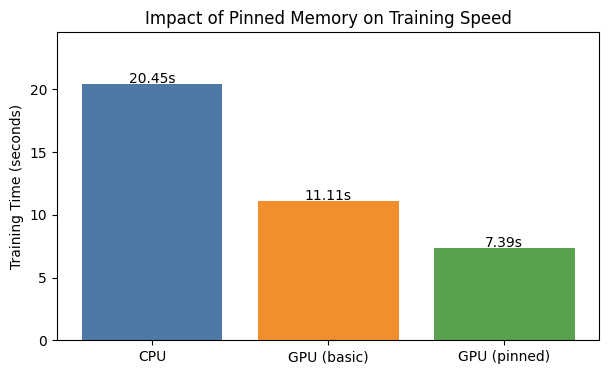

In [13]:
labels = ['CPU', 'GPU (basic)', 'GPU (pinned)']
times = [cpu_time, gpu_basic_time, gpu_pinned_time]

plt.figure(figsize=(7, 4))
bars = plt.bar(labels, times, color=['#4e79a7', '#f28e2b', '#59a14f'])
plt.ylabel('Training Time (seconds)')
plt.title('Impact of Pinned Memory on Training Speed')
for i, (bar, t) in enumerate(zip(bars, times)):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05, f'{t:.2f}s', ha='center')
plt.ylim(0, max(times)*1.2)
plt.show()

### Optimization 1.2: asynchronous transfers


In [14]:
print("⏳ Running GPU training with pinned memory and asynchronous data transfer...")
gpu_pinned_async_time = train_gpu_pinned(n_epochs=1, ASYNC_DATATRANSFER=True)
print(f"✅ GPU (pinned+async) training time: {gpu_pinned_async_time:.2f} seconds")
print(f"📈 Speedup vs basic GPU: {gpu_basic_time/gpu_pinned_async_time:.2f}x")

⏳ Running GPU training with pinned memory and asynchronous data transfer...
✅ GPU (pinned+async) training time: 6.45 seconds
📈 Speedup vs basic GPU: 1.72x


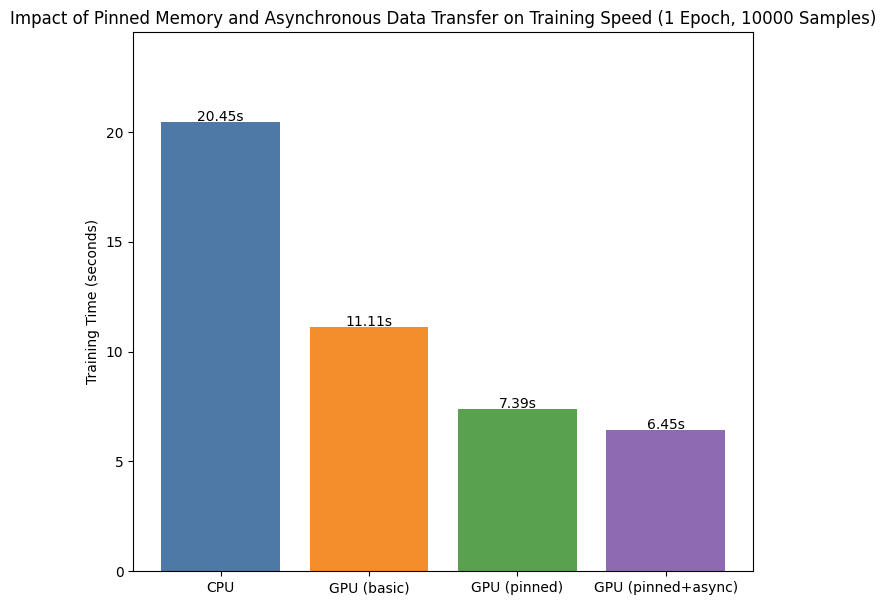

In [15]:
labels = ['CPU', 'GPU (basic)', 'GPU (pinned)', 'GPU (pinned+async)']
times = [cpu_time, gpu_basic_time, gpu_pinned_time, gpu_pinned_async_time]

plt.figure(figsize=(8, 7))
bars = plt.bar(labels, times, color=['#4e79a7', '#f28e2b', '#59a14f', '#8e6ab3'])
plt.ylabel('Training Time (seconds)')
plt.title('Impact of Pinned Memory and Asynchronous Data Transfer on Training Speed (1 Epoch, 10000 Samples)')
for i, (bar, t) in enumerate(zip(bars, times)):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05, f'{t:.2f}s', ha='center')
plt.ylim(0, max(times)*1.2)
plt.show()

## 5.  Influence of Batch Size 

⚡ Training on GPU with pinned memory (batch_size=16, async_transfer=True)...
  Epoch 1/10...
  Epoch 2/10...
  Epoch 3/10...
  Epoch 4/10...
  Epoch 5/10...
  Epoch 6/10...
  Epoch 7/10...
  Epoch 8/10...
  Epoch 9/10...
  Epoch 10/10...
⚡ Training on GPU with pinned memory (batch_size=32, async_transfer=True)...
  Epoch 1/10...
  Epoch 2/10...
  Epoch 3/10...
  Epoch 4/10...
  Epoch 5/10...
  Epoch 6/10...
  Epoch 7/10...
  Epoch 8/10...
  Epoch 9/10...
  Epoch 10/10...
⚡ Training on GPU with pinned memory (batch_size=64, async_transfer=True)...
  Epoch 1/10...
  Epoch 2/10...
  Epoch 3/10...
  Epoch 4/10...
  Epoch 5/10...
  Epoch 6/10...
  Epoch 7/10...
  Epoch 8/10...
  Epoch 9/10...
  Epoch 10/10...
⚡ Training on GPU with pinned memory (batch_size=128, async_transfer=True)...
  Epoch 1/10...
  Epoch 2/10...
  Epoch 3/10...
  Epoch 4/10...
  Epoch 5/10...
  Epoch 6/10...
  Epoch 7/10...
  Epoch 8/10...
  Epoch 9/10...
  Epoch 10/10...
⚡ Training on GPU with pinned memory (batch_siz

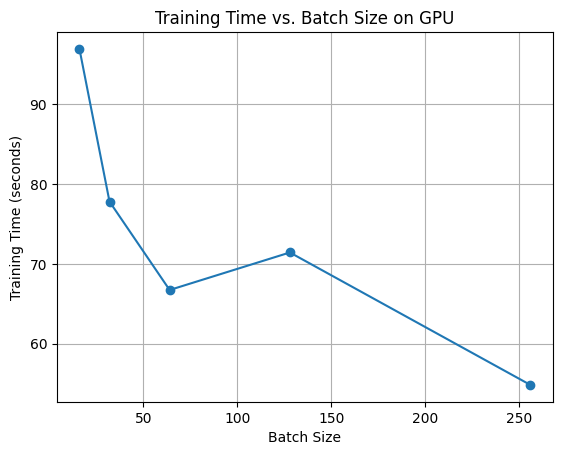

In [ ]:
import time


n_epochs = 10  
learning_rate = 0.01
momentum = 0.9
batch_sizes = [16, 32, 64, 128, 256]  
     
# Measure training time for each batch size
times = []
for batch_size in batch_sizes:
    training_time = train_gpu_pinned(n_epochs=n_epochs, lr=learning_rate, batch_size=batch_size, momentum=momentum, ASYNC_DATATRANSFER=True)
    times.append(training_time)

# Plot the results
plt.plot(batch_sizes, times, marker='o')
plt.xlabel('Batch Size')
plt.ylabel('Training Time (seconds)')
plt.title('Training Time vs. Batch Size on GPU')
plt.grid()
plt.show()

In [27]:
print("✅ All experiments completed successfully!")
print("📊 Summary of training times:")
for i, (batch_size, time) in enumerate(zip(batch_sizes, times)):
    print(f"  Batch Size: {batch_size}, Training Time: {time:.2f} seconds")

✅ All experiments completed successfully!
📊 Summary of training times:
  Batch Size: 16, Training Time: 96.89 seconds
  Batch Size: 32, Training Time: 77.79 seconds
  Batch Size: 64, Training Time: 66.72 seconds
  Batch Size: 128, Training Time: 71.42 seconds
  Batch Size: 256, Training Time: 54.84 seconds


####  Overall Trend

The general trend is that **larger batch sizes reduce the total training time**.

This happens because a GPU is designed to execute thousands of operations in parallel. With a small batch size, many CUDA cores remain idle because there is not enough work to keep them busy. As the batch size increases, the GPU becomes better utilized, so each kernel launch performs more useful computation.

For example:

* **Batch size = 16:** GPU utilization is relatively low, leading to the longest training time (96.89 s).
* **Batch size = 32:** The GPU receives twice as much work per iteration, reducing the training time by about **20%**.
* **Batch size = 64:** GPU utilization improves further, reducing the time to **66.72 s**.
* **Batch size = 256:** The GPU is used much more efficiently, giving the shortest training time (**54.84 s**).

### Why does Batch Size 128 become slower?

The increase from **66.72 s** (batch size 64) to **71.42 s** (batch size 128) is not unusual and can occur for several reasons:

* Normal timing variability due to other system processes.
* CUDA kernel scheduling differences.
* Memory allocation overhead.
* Data loading fluctuations.
* Thermal throttling or temporary GPU frequency changes.

Since the slowdown is only about **7%**, it is likely due to measurement noise rather than a fundamental performance issue.


### Why does Batch Size 256 perform best?

With a larger batch:

* fewer iterations are required to process one epoch,
* fewer CUDA kernel launches occur,
* fewer optimizer updates are performed,
* the GPU spends more time computing and less time waiting.

As a result, the total training time is minimized.

### Performance Improvement

Compared to the smallest batch:

* Batch Size **16**: **96.89 s**
* Batch Size **256**: **54.84 s**

This corresponds to

[
\frac{96.89-54.84}{96.89}\times100 \approx 43.4%
]

So using a batch size of **256 reduces the training time by approximately 43%** compared to a batch size of 16.

### Recap

The experiment demonstrates that increasing the batch size generally improves GPU training performance by increasing hardware utilization and reducing per-iteration overhead. Although the training time slightly increases at batch size 128, this is most likely due to normal experimental variability. Overall, **batch size 256 provides the best performance**, reducing the total training time by approximately **43%** compared to batch size 16 while making the most efficient use of the GPU.

**Teaching note:** If this experiment is for students, it's a good opportunity to emphasize that **performance benchmarking should never rely on a single run**. GPU timings naturally fluctuate, so each configuration should be executed multiple times (e.g., 5–10 runs) and the average (and ideally the standard deviation) should be reported. This would likely smooth out the anomaly observed at batch size 128.


---
## 5. Optimization 2: Multi-Process Data Loading (`num_workers > 0`)

While pinned memory speeds up *transfer*, the CPU might still be slow at preprocessing (e.g., `ToTensor`, `Normalize`).

### Solution: Use multiple CPU workers
```python
DataLoader(..., num_workers=4)
```

⚠️ Trade-off: More workers = more overhead. But for large datasets, it's worth it!

But beware: too many workers cause overhead (process spawning, GIL contention). Let’s find the sweet spot!

In [43]:
import os 

print(os.cpu_count())

20


In [13]:
import time
train_set = datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)

batch_size = 256

def train_with_workers(num_workers, n_epochs=1):
    model = Net().to(device)
    optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.9)
    criterion = nn.CrossEntropyLoss()
    
    train_loader = DataLoader(train_set, batch_size=batch_size,shuffle=True,
                              num_workers=num_workers, pin_memory=True)
    
    start = time.time()
    model.train()
    print(f"⚡ Training on GPU with num_workers={num_workers}...")
    for epoch in range(n_epochs):
        print(f"  Epoch {epoch+1}/{n_epochs}...")
        for data, target in train_loader:
            data, target = data.to(device), target.to(device)
            optimizer.zero_grad()
            output = model(data)
            loss = criterion(output, target)
            loss.backward()
            optimizer.step()
    return time.time() - start

In [41]:
workers = [0, 1 ,2, 4, 8]
times_workers = []

print("⚙️ Testing num_workers =", workers)
for w in workers:
    t = train_with_workers(w, n_epochs=1)
    times_workers.append(t)
    print(f"  num_workers={w:2d}: {t:.2f}s")

⚙️ Testing num_workers = [0, 1, 2, 4, 8]
⚡ Training on GPU with num_workers=0...
  Epoch 1/1...
  num_workers= 0: 65.37s
⚡ Training on GPU with num_workers=1...
  Epoch 1/1...
  num_workers= 1: 42.60s
⚡ Training on GPU with num_workers=2...
  Epoch 1/1...
  num_workers= 2: 43.76s
⚡ Training on GPU with num_workers=4...
  Epoch 1/1...
  num_workers= 4: 70.75s
⚡ Training on GPU with num_workers=8...
  Epoch 1/1...
  num_workers= 8: 123.77s


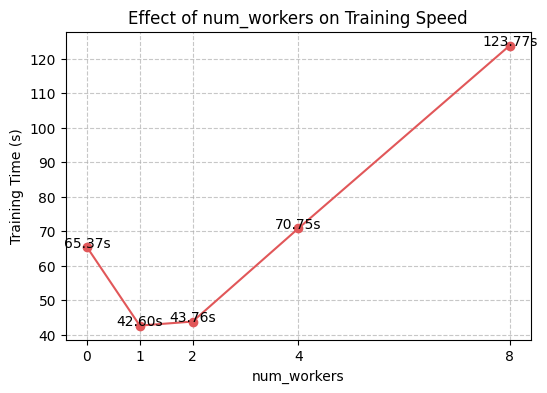

In [42]:
plt.figure(figsize=(6, 4))
plt.plot(workers, times_workers, marker='o', color='#e15759')
plt.xlabel('num_workers')
plt.ylabel('Training Time (s)')
plt.title('Effect of num_workers on Training Speed')
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(workers)
for w, t in zip(workers, times_workers):
    plt.text(w, t+0.02, f'{t:.2f}s', ha='center')
plt.show()

✅ **Observation**: 
- `num_workers=0`: slow (single thread)
- `num_workers=1 or 2`: fastest (matches typical CPU core count)
- `num_workers=8`: slower again (overhead dominates)

**Rule of thumb**: Start with `num_workers = min(4, os.cpu_count())`.

In [42]:
import os 

print(os.cpu_count())

20


---
## 7. Optimization : Automatic Mixed Precision (AMP)

### What is AMP?
Modern GPUs (Volta+, Turing+, Ampere+) have specialized **Tensor Cores** that operate on **float16 (fp16)** data at up to **8x** the throughput of float32 (fp32).

AMP uses the `torch.cuda.amp` module to automatically:
- Use **fp16** for compute-heavy ops (conv2d, linear) faster
- Keep **fp32** for ops that need precision (loss, reductions) no accuracy loss
- Use a `GradScaler` to prevent underflow in small gradients

### Three modes to compare:
| Mode | Description |
|------|-------------|
| **fp32** | Full single precision (baseline) |
| **fp16** | Pure half precision (model + data cast to fp16) |
| **AMP** | Automatic mixed precision (smart hybrid) |

In [14]:
train_set = datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)

In [ ]:
import torch, time, gc

# Timing utilities
start_time = None

def start_timer():
    global start_time
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_max_memory_allocated()
    torch.cuda.synchronize()
    start_time = time.time()

def end_timer_and_print(local_msg):
    torch.cuda.synchronize()
    end_time = time.time()
    elapsed_time = end_time - start_time
    memory = torch.cuda.torch.cuda.reset_peak_memory_stats()/1024**2  # Convert bytes to MB
    print("\n" + local_msg)
    print("Total execution time = {:.3f} sec".format(end_time - start_time))
    print("Max memory used by tensors = {:.2f} MB".format(memory))
    return elapsed_time, memory

In [30]:
num_workers = 1
batch_size = 1024
epochs = 5
train_loader = DataLoader(train_set, batch_size=batch_size,shuffle=True,
                                  num_workers=num_workers, pin_memory=True)  

In [ ]:
def train_config():

    torch.manual_seed(42)
    torch.cuda.manual_seed_all(42)
    model = Net().to(device)
    optimizer = optim.SGD(model.parameters(),lr=0.01,momentum=0.9)
    criterion = nn.CrossEntropyLoss()
    model.train()

    return model, optimizer, criterion

### Default Precision (fp32)

In [ ]:
print(
    "Allocated:",
    torch.cuda.memory_allocated()/1024**2,
    "MB"
)

print(
    "Reserved:",
    torch.cuda.memory_reserved()/1024**2,
    "MB"
)

Allocated: 45.12255859375 MB
Reserved: 318.0 MB


In [ ]:
model, optimizer, criterion = train_config()

start_timer()

for epoch in range(epochs):

    for data, target in train_loader:

        data = data.to(device, non_blocking=True)
        target = target.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        output = model(data)

        loss = criterion(output, target)

        loss.backward()

        optimizer.step()

    end_timer_and_print(f"Epoch {epoch+1}/{epochs} completed")

fp32_time, fp32_memory = end_timer_and_print("Default Precision (FP32)")


Epoch 1/5 completed
Total execution time = 19.219 sec
Max memory used by tensors = 282387456 bytes

Epoch 2/5 completed
Total execution time = 31.971 sec
Max memory used by tensors = 282387456 bytes

Epoch 3/5 completed
Total execution time = 44.315 sec
Max memory used by tensors = 282387456 bytes

Epoch 4/5 completed
Total execution time = 57.708 sec
Max memory used by tensors = 282387456 bytes

Epoch 5/5 completed
Total execution time = 72.182 sec
Max memory used by tensors = 282387456 bytes

Default Precision (FP32)
Total execution time = 72.183 sec
Max memory used by tensors = 282387456 bytes


#### adding autocast

In [ ]:
model, optimizer, criterion = train_config()

start_timer()

for epoch in range(epochs):

    for data, target in train_loader:

        data = data.to(device, non_blocking=True)
        target = target.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
        ):

            output = model(data)

            loss = criterion(output, target)

        loss.backward()

        optimizer.step()
        
    end_timer_and_print(f"Epoch {epoch+1}/{epochs} completed")

autocast_time, autocast_memory = end_timer_and_print("Autocast Only")


Epoch 1/5 completed
Total execution time = 12.647 sec
Max memory used by tensors = 200665600 bytes

Epoch 2/5 completed
Total execution time = 24.702 sec
Max memory used by tensors = 200665600 bytes

Epoch 3/5 completed
Total execution time = 36.442 sec
Max memory used by tensors = 200665600 bytes

Epoch 4/5 completed
Total execution time = 48.469 sec
Max memory used by tensors = 200665600 bytes

Epoch 5/5 completed
Total execution time = 60.180 sec
Max memory used by tensors = 200665600 bytes

Autocast Only
Total execution time = 60.181 sec
Max memory used by tensors = 200665600 bytes


### Automatic Mixed Precision (AMP)

**Add a Warmup Epoch Before Timing** 

Benchmarking the first epoch measures JIT compilation time, not training speed. Because torch.compile operates Just-In-Time (JIT), the very first step of training will be slow while PyTorch generates and compiles the optimized CUDA code. You must run a "warmup" epoch before calling start_timer().

In [ ]:
model, optimizer, criterion = train_config()

scaler = torch.amp.GradScaler("cuda")

print("Running warmup epoch for AMP (compiling kernels)...")
for data, target in train_loader:
    data, target = data.to(device, non_blocking=True), target.to(device, non_blocking=True)
    optimizer.zero_grad(set_to_none=True)
    with torch.autocast(device_type="cuda", dtype=torch.float16):
        loss = criterion(model(data), target)
    scaler.scale(loss).backward()
    scaler.step(optimizer)
    scaler.update()

Running warmup epoch for AMP (compiling kernels)...


In [ ]:
model, optimizer, criterion = train_config()

scaler = torch.amp.GradScaler("cuda")

start_timer()

for epoch in range(epochs):

    for data, target in train_loader:

        data = data.to(device, non_blocking=True)
        target = target.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
        ):

            output = model(data)

            loss = criterion(output, target)

        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()

    end_timer_and_print(f"Epoch {epoch+1}/{epochs} completed")

amp_time, amp_memory=end_timer_and_print("Automatic Mixed Precision (AMP)")

Epoch 1/5

Epoch 1/5 completed
Total execution time = 12.130 sec
Max memory used by tensors = 202882048 bytes
Epoch 2/5

Epoch 2/5 completed
Total execution time = 24.276 sec
Max memory used by tensors = 202882048 bytes
Epoch 3/5

Epoch 3/5 completed
Total execution time = 36.395 sec
Max memory used by tensors = 202882048 bytes
Epoch 4/5

Epoch 4/5 completed
Total execution time = 48.418 sec
Max memory used by tensors = 202882048 bytes
Epoch 5/5

Epoch 5/5 completed
Total execution time = 60.299 sec
Max memory used by tensors = 202882048 bytes

Automatic Mixed Precision (AMP)
Total execution time = 60.300 sec
Max memory used by tensors = 202882048 bytes



Generating dashboard with live hardware measurements...


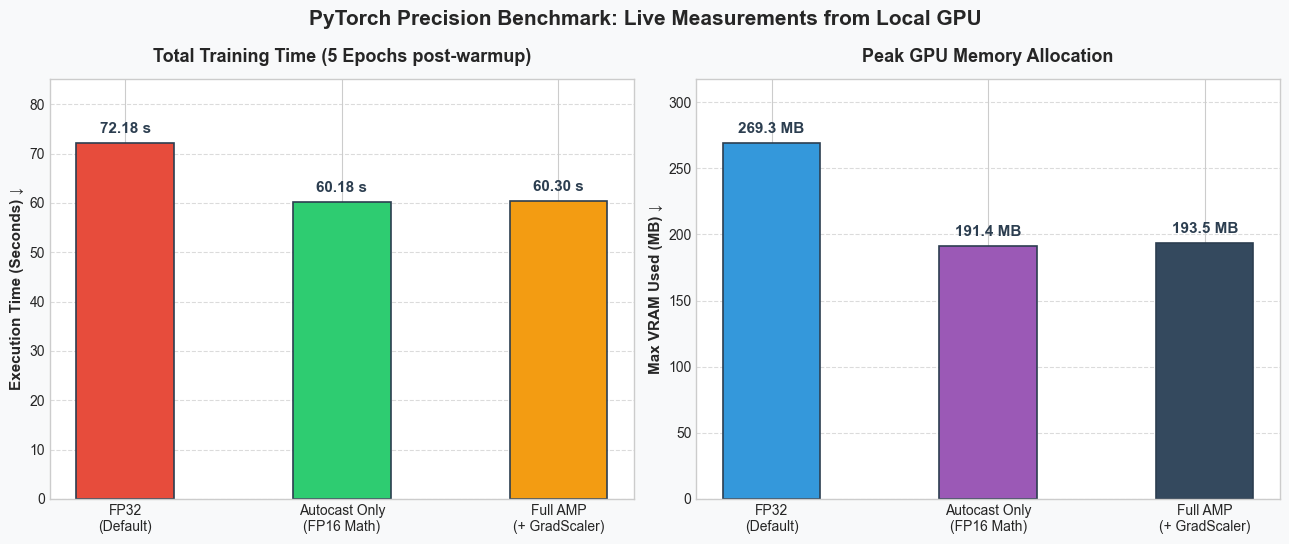

In [46]:
print("\nGenerating dashboard with live hardware measurements...")

# Dynamically populate arrays with real variables
modes = ['FP32\n(Default)', 'Autocast Only\n(FP16 Math)', 'Full AMP\n(+ GradScaler)']
times_sec = [fp32_time, autocast_time, amp_time]       
vram_mb = [fp32_memory, autocast_memory, amp_memory]      

# Setup Figure and Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))
fig.patch.set_facecolor('#f8f9fa')

# --- PLOT 1: Execution Time (Lower is Better) ---
colors_time = ['#e74c3c', '#2ecc71', '#f39c12']
bars1 = ax1.bar(modes, times_sec, color=colors_time, width=0.45, edgecolor='#2c3e50', linewidth=1.2)

ax1.set_title(f'Total Training Time ({epochs} Epochs post-warmup)', fontsize=13, fontweight='bold', pad=12)
ax1.set_ylabel('Execution Time (Seconds) ↓', fontsize=11, fontweight='bold')
ax1.set_ylim(0, max(times_sec) * 1.18)
ax1.grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars1:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height + (max(times_sec) * 0.02),
             f'{height:.2f} s',
             ha='center', va='bottom', fontsize=11, fontweight='bold', color='#2c3e50')

# --- PLOT 2: Peak VRAM Allocation (Lower is Better) ---
colors_vram = ['#3498db', '#9b59b6', '#34495e']
bars2 = ax2.bar(modes, vram_mb, color=colors_vram, width=0.45, edgecolor='#2c3e50', linewidth=1.2)

ax2.set_title('Peak GPU Memory Allocation', fontsize=13, fontweight='bold', pad=12)
ax2.set_ylabel('Max VRAM Used (MB) ↓', fontsize=11, fontweight='bold')
ax2.set_ylim(0, max(vram_mb) * 1.18)
ax2.grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars2:
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height + (max(vram_mb) * 0.02),
             f'{height:.1f} MB',
             ha='center', va='bottom', fontsize=11, fontweight='bold', color='#2c3e50')

# Final Layout Adjustments
plt.suptitle('PyTorch Precision Benchmark: Live Measurements from Local GPU', fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

---
## Interactive Experiment: Tune Your Own Settings

Use the widget below to adjust `batch_size`, `num_workers`, and `pin_memory`, then see how training time changes.

> 💡 Hint: Try `batch_size=128`, `num_workers=4`, `pin_memory=True`

In [ ]:
# Interactive widget
batch_slider = widgets.IntSlider(value=64, min=16, max=256, step=16, description='Batch Size:')
workers_slider = widgets.IntSlider(value=4, min=0, max=8, step=1, description='num_workers:')
pin_toggle = widgets.Checkbox(value=True, description='pin_memory')
run_btn = widgets.Button(description="Run Training")
output = widgets.Output()

def on_run_clicked(b):
    with output:
        clear_output(wait=True)
        print("Running... please wait (1 epoch)")
        try:
            t = train_with_workers(
                num_workers=workers_slider.value,
                n_epochs=1
            )
            # Rebuild DataLoader with new params
            model = Net().to(device)
            optimizer = optim.SGD(model.parameters(), lr=0.01)
            criterion = nn.CrossEntropyLoss()
            
            train_loader = DataLoader(train_set, batch_size=batch_slider.value, 
                                      sampler=train_sampler, 
                                      num_workers=workers_slider.value, 
                                      pin_memory=pin_toggle.value)
            
            start = time.time()
            model.train()
            for data, target in train_loader:
                data, target = data.to(device), target.to(device)
                optimizer.zero_grad()
                output_model = model(data)
                loss = criterion(output_model, target)
                loss.backward()
                optimizer.step()
                break  # only 1 batch for speed
            end = time.time()
            print(f"✅ Time: {end-start:.3f}s | batch={batch_slider.value}, workers={workers_slider.value}, pin={pin_toggle.value}")
        except Exception as e:
            print(f"❌ Error: {e}")

run_btn.on_click(on_run_clicked)

display(widgets.VBox([batch_slider, workers_slider, pin_toggle, run_btn, output]))

---
## X. Putting It All Together: Best Practice Setup

#### Your turn

## Your Turn: Build the Full Training Loop and Benchmark It

Create a training loop that combines everything learned so far:

- move the model to GPU with `.to(device)`
- enable `pin_memory=True` in the `DataLoader`
- use `num_workers > 0`
- transfer tensors with `non_blocking=True`
- optionally benchmark `AMP` with `autocast` and `GradScaler`

Use the function to compare multiple configurations and identify the fastest setup for your machine.

- move the model to GPU with `.to(device)`
- use `pin_memory=True`
- use `num_workers > 0`
- use `non_blocking=True` when transferring tensors
- optionally test `AMP` with `autocast` and `GradScaler`

### Goal
Write one optimized training function, then benchmark it against the previous versions.

### What to measure
- training time
- GPU memory usage
- effect of batch size
- effect of `num_workers`
- effect of `pin_memory`

### Expected result
You should compare several configurations and identify the fastest setup for your machine.

---
## 📚 Key Takeaways

| Technique | What it does | When to use |
|----------|--------------|-------------|
| `.to('cuda')` | Moves model/params to GPU | Always (if GPU available) |
| `pin_memory=True` | Enables fast DMA host→device copies | Almost always in training |
| `num_workers>0` | Parallelizes data loading/preprocessing | When CPU is underutilized |
| Async streams (advanced) | Overlaps data transfer + compute | For maximum throughput (use `non_blocking=True`) |

### Why this matters:
- Modern GPUs are *hundreds* of times faster than CPUs for matrix ops — but only if fed data fast enough.
- The **data pipeline is often the bottleneck**, not the GPU compute.
- Small tweaks (`pin_memory`, `num_workers`) give **2–5x speedups** with zero model change.

You’ve just replicated the exact optimizations used in production DL systems (PyTorch Lightning, Hugging Face, etc.) — great job! 🎉

---
## 🧩 Bonus: Try It Yourself

1. **Challenge**: Modify `train_optimized()` to use `non_blocking=True` in `.to(device, non_blocking=True)`. Does it help?
2. **Deep Dive**: Profile with `torch.profiler` again — compare `cuda_time` before/after `pin_memory`.
3. **Real-world**: Scale to full CIFAR-10 (50k samples) — how do times scale?

In [49]:
# 🙌 Thank you for exploring CUDA acceleration!
print("\n🎉 You've mastered the art of GPU-accelerated deep learning.\n")
print("Next steps: The second Project involves optimization of a larger Network, it's mobile net. This your turn to show what you have learned. ")


🎉 You've mastered the art of GPU-accelerated deep learning.

Next steps: The second Project involves optimization of a larger Network, it's mobile net. This your turn to show what you have learned. 
